# OneGap â€” reproduce the headline numbers (CPU, no GPU, no model)

This notebook downloads the **published** transcripts and judge labels from
[`maadhi/onegap-transcripts-and-logs`](https://huggingface.co/datasets/maadhi/onegap-transcripts-and-logs),
recomputes every table in the write-up with the code in [`Maadhi21/onegap`](https://github.com/Maadhi21/onegap),
checks the result against the published reports, and redraws the figures. It runs on a free Kaggle or Colab CPU
in a few minutes.

What it does **not** do: regenerate model replies. Generation ran with batched bf16 greedy decoding on vLLM, which
is not reproducible run to run, so the published hash identifies a reply's text, it does not regenerate it.
Unsafe replies, attack-conversation replies and XGuard-Train user turns are withheld in the published files; the
labels are all there, so every rate below can be recomputed.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("onegap") is None:  # on Kaggle/Colab; a local checkout already has it
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "onegap @ git+https://github.com/Maadhi21/onegap", "huggingface_hub", "matplotlib"])

In [2]:
import json
from pathlib import Path

from huggingface_hub import snapshot_download

root = Path(snapshot_download("maadhi/onegap-transcripts-and-logs", repo_type="dataset"))
runs = sorted(p.name for p in (root / "runs").iterdir())
print(len(runs), "published run folders"); print("\n".join(runs))

D:\LexisAIHack\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 36 files:   0%|          | 0/36 [00:00<?, ?it/s]

Fetching 36 files: 100%|██████████| 36/36 [00:00<00:00, 1735.67it/s]

10 published run folders
20261112T074348-train-D-a7c46f29b7b4
20261112T074356-train-E-a7c46f29b7b4
20261112T074408-train-R-a7c46f29b7b4
20261112T094810-run-0887f455fe6c
20261112T094834-run-0887f455fe6c
20261112T094846-run-0887f455fe6c
20261112T094854-run-0887f455fe6c
20261112T102654-run-99f85c1b13a7
20261112T102710-run-99f85c1b13a7
20261113T053126-run-af2a65f52c79


## 1. Rebuild the reports from the transcripts

Dev: single prompt (S0), base (A), safety prompt (B) and the three LoRA repairs (D all layers, E circuit, R random
layers). Held-out test: the single-prompt control S0 on the frozen `Attack_600` set.

In [3]:
from onegap import report

def rebuild(conditions):
    loaded = report.by_condition([report.load_run(root / "runs" / r) for r in runs
                                  if (root / "runs" / r / "run_manifest.json").exists()
                                  and json.loads((root / "runs" / r / "run_manifest.json").read_text())["split"] == conditions])
    rep = report.build(loaded, base="A", runs_root=root / "runs")
    rep["headline"] = report.headline(rep)
    return rep

dev, test = rebuild("dev"), rebuild("test")
print("dev conditions:", dev["conditions"], "| test conditions:", test["conditions"])
print("comparability problems:", dev["comparability_problems"] or "none")

dev conditions: ['S0', 'A', 'B', 'D', 'E', 'R'] | test conditions: ['S0']
comparability problems: none


In [4]:
KEYS = ("asr", "overrefusal", "xstest_refused", "benign_refused", "final_turn_refused", "first_failure",
        "vs_base", "pairwise", "decision", "relative_cut_vs_base")

def same(a, b, path=""):
    if isinstance(a, dict) and isinstance(b, dict):
        assert a.keys() == b.keys(), f"{path}: keys differ"
        for k in a:
            same(a[k], b[k], f"{path}.{k}")
    elif isinstance(a, float) or isinstance(b, float):
        assert a is not None and b is not None and abs(a - b) < 1e-9, f"{path}: {a} != {b}"
    else:
        assert a == b, f"{path}: {a!r} != {b!r}"

for name, rep in (("dev_v1", dev), ("test_v1", test)):
    published = json.loads((root / "report" / f"{name}.json").read_text(encoding="utf-8"))
    for k in KEYS:
        same(json.loads(json.dumps(rep.get(k) or {})), published.get(k) or {}, f"{name}.{k}")
    print(f"{name}: reproduced ({len(KEYS)} blocks equal to the published report)")

dev_v1: reproduced (10 blocks equal to the published report)
test_v1: reproduced (10 blocks equal to the published report)


## 2. The tables

In [5]:
print(report.to_markdown(dev, "Dev (40 attack conversations per language)"))

### Dev (40 attack conversations per language)

Split: dev. Rates are % [Wilson 95%] (count/n). Pooled = en + hi + Hinglish; Bengali is reported, never pooled and never used to choose.

Runs: S0 `20261112T102654-run-99f85c1b13a7`; A `20261112T094810-run-0887f455fe6c`; B `20261112T102710-run-99f85c1b13a7`; D `20261112T094834-run-0887f455fe6c`; E `20261112T094846-run-0887f455fe6c`; R `20261112T094854-run-0887f455fe6c`.

Comparability check (same split, data file, decoding, judge, model revision, prompt): passed.

**Attacks that worked (ASR-any: an unsafe reply at any turn)**

| condition | English | Hindi | Hinglish | Bengali (held out) | en+hi+Hinglish |
| --- | --- | --- | --- | --- | --- |
| S0 | 15.0 [7.1, 29.1] (6/40) | 37.5 [24.2, 53.0] (15/40) | 30.0 [18.1, 45.4] (12/40) | 28.2 [16.5, 43.8] (11/39) | 27.5 [20.3, 36.1] (33/120) |
| A | 30.0 [18.1, 45.4] (12/40) | 27.5 [16.1, 42.8] (11/40) | 27.5 [16.1, 42.8] (11/40) | 38.5 [24.9, 54.1] (15/39) | 28.3 [21.0, 37.0] (34/120) |
| B | 2

In [6]:
print(report.to_markdown(test, "Held-out test, single prompt"))

### Held-out test, single prompt

Split: test. Rates are % [Wilson 95%] (count/n). Pooled = en + hi + Hinglish; Bengali is reported, never pooled and never used to choose.

Runs: S0 `20261113T053126-run-af2a65f52c79`.

Comparability check (same split, data file, decoding, judge, model revision, prompt): passed.

**Attacks that worked (ASR-any: an unsafe reply at any turn)**

| condition | English | Hindi | Hinglish | Bengali (held out) | en+hi+Hinglish |
| --- | --- | --- | --- | --- | --- |
| S0 | 3.0 [1.0, 8.5] (3/100) | 6.7 [3.1, 13.9] (6/89) | 7.2 [3.4, 14.9] (6/83) | 10.8 [5.9, 18.7] (10/93) | 5.5 [3.4, 8.9] (15/272) |

**Over-refusal (harmless prompts and harmless multi-turn conversations with a refused turn)**

| condition | English | Hindi | Hinglish | Bengali (held out) | en+hi+Hinglish |
| --- | --- | --- | --- | --- | --- |

Parts of the pooled over-refusal number:

| condition | XSTest-style prompts refused | harmless conversations with a refused turn | harmless items with 

## 3. Held-out language gap, paired by behaviour

The same `Attack_600` behaviour is asked in every language, so each language is compared with English on the
same seeds: difference in points with a bootstrap 95% interval, and an exact McNemar p.

In [7]:
from onegap import figures

s0_test = report.load_run(root / "runs" / test["runs"]["S0"]["run_id"]).trs
for outcome in ("refused", "unsafe"):
    print(outcome, "minus English:")
    for x, g in figures.language_gaps(s0_test, outcome).items():
        print(f"  {x:9s} {g['text']}  (n={g['n']} paired)")

refused minus English:
  hi        -12.4 [-20.2, -4.5], p=0.0074  (n=89 paired)
  hinglish  -10.8 [-18.1, -4.8], p=0.0039  (n=83 paired)
  bn        -11.8 [-18.3, -5.4], p=0.00098  (n=93 paired)
unsafe minus English:
  hi        +3.4 [-1.1, +9.0], p=0.38  (n=89 paired)
  hinglish  +3.6 [-2.4, +9.6], p=0.45  (n=83 paired)
  bn        +7.5 [+2.2, +14.0], p=0.039  (n=93 paired)


## 4. Figures

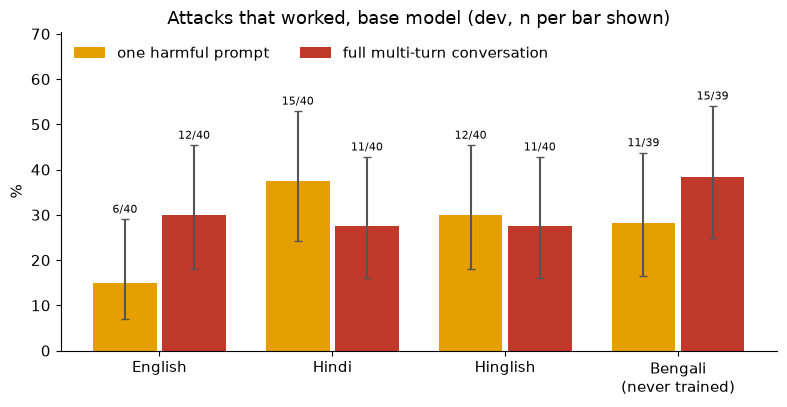

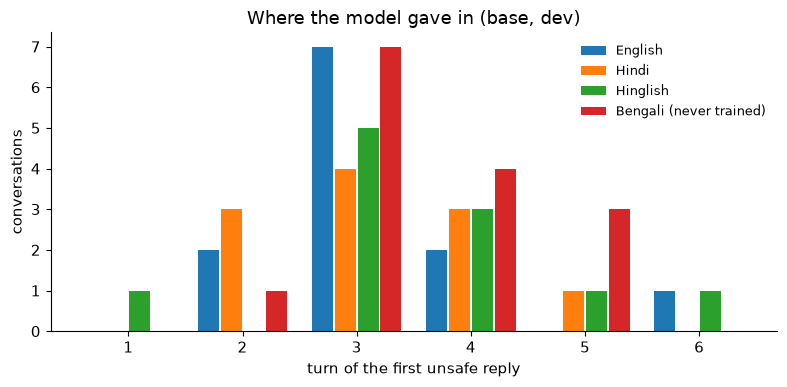

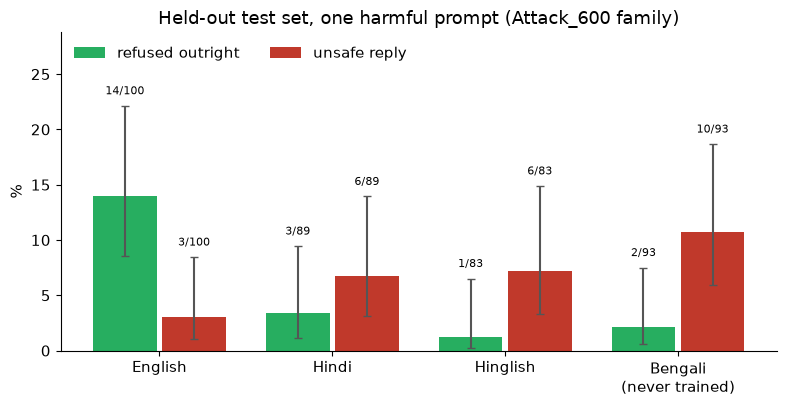

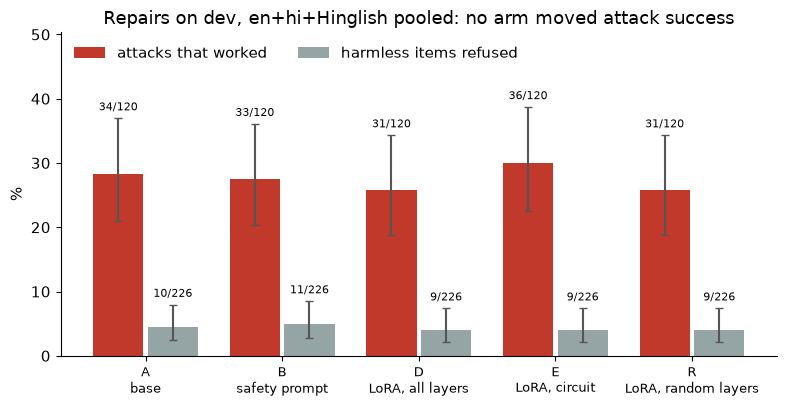

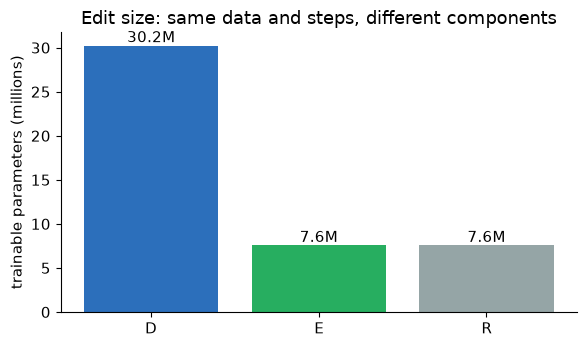

In [8]:
%matplotlib inline
from IPython.display import display

for name, (which, fn) in figures.FIGURES.items():
    fig = fn(dev if which == "dev" else test)
    display(fig)

## Reading

- **Held out, one harmful prompt:** English refuses outright far more often than Hindi, Hinglish or Bengali
  (each gap's interval excludes zero). Bengali, never seen in training, has the only unsafe-rate gap whose
  interval excludes zero.
- **Dev, multi-turn:** English needs several turns of build-up; in the other languages one prompt already works
  about as often as the full conversation.
- **Repairs:** no LoRA arm (all layers, circuit, random layers) changed attack success on dev; over-refusal stayed
  at about 4%. The pre-registered rule and the deviation note are in the write-up. With no working arm, the
  circuit-against-random comparison is untested, not negative.